<a href="https://colab.research.google.com/github/EzhilOvea/Invoque_Titanic-survival-prediction-system/blob/main/titanic_survival_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


In [4]:
t_data=pd.read_csv('/content/train.csv')
t_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
t_data.shape

(891, 12)

In [6]:
t_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
t_data.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [8]:
t_data=t_data.drop(columns='Cabin',axis=1)


In [9]:
t_data['Age'].fillna(t_data['Age'].mean(),inplace=True)
t_data['Embarked'].fillna(t_data['Embarked'].mode()[0],inplace=True)

/tmp/ipykernel_2204/1520187818.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  t_data['Age'].fillna(t_data['Age'].mean(),inplace=True)
/tmp/ipykernel_2204/1520187818.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)

In [10]:
t_data.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


<Axes: xlabel='Sex', ylabel='count'>

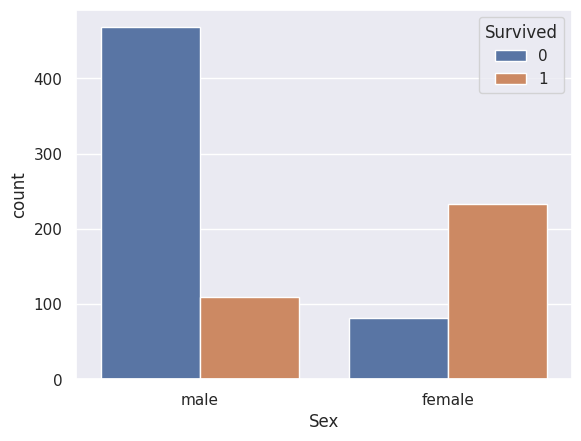

In [11]:
sns.set_theme()
sns.countplot(x='Sex',hue='Survived',data=t_data)

<Axes: xlabel='Age', ylabel='count'>

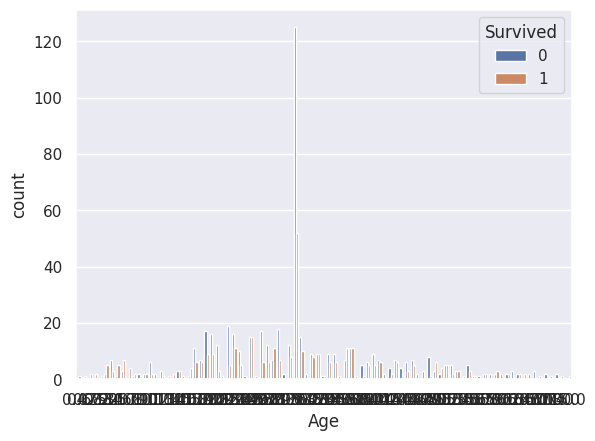

In [12]:
sns.set_theme()
sns.countplot(x='Age',hue='Survived',data=t_data)


In [13]:
t_data['Age'].value_counts()

,count
Age,
29.699118,177
24.000000,30
22.000000,27
18.000000,26
28.000000,25
...,...
24.500000,1
0.670000,1
0.420000,1


In [14]:
t_data['Embarked'].value_counts()

,count
Embarked,
S,646
C,168
Q,77


In [15]:
t_data.replace({'Sex':{'male':0,'female':1},'Embarked':{'S':0,'C':1,'Q':2}},inplace=True)
print(t_data)

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name  Sex        Age  SibSp  \
0                              Braund, Mr. Owen Harris    0  22.000000      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...    1  38.000000      1   
2                               Heikkinen, Miss. Laina    1  26.000000      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)    1  35.000000      1   
4                             Allen, Mr. William Henry    0  35.000000      0   
..                                                 ...  .

/tmp/ipykernel_2204/4284329087.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  t_data.replace({'Sex':{'male':0,'female':1},'Embarked':{'S':0,'C':1,'Q':2}},inplace=True)


In [16]:
x=t_data.drop(columns=['PassengerId','Name','Ticket','Survived'],axis=1)
y=t_data['Survived']

In [17]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [18]:
print(x_train,y_train)

     Pclass  Sex        Age  SibSp  Parch      Fare  Embarked
30        1    0  40.000000      0      0   27.7208         1
10        3    1   4.000000      1      1   16.7000         0
873       3    0  47.000000      0      0    9.0000         0
182       3    0   9.000000      4      2   31.3875         0
876       3    0  20.000000      0      0    9.8458         0
..      ...  ...        ...    ...    ...       ...       ...
534       3    1  30.000000      0      0    8.6625         0
584       3    0  29.699118      0      0    8.7125         1
493       1    0  71.000000      0      0   49.5042         1
527       1    0  29.699118      0      0  221.7792         0
168       1    0  29.699118      0      0   25.9250         0

[712 rows x 7 columns] 30     0
10     1
873    0
182    0
876    0
      ..
534    0
584    0
493    0
527    0
168    0
Name: Survived, Length: 712, dtype: int64


In [19]:
model=LogisticRegression()
model.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [20]:
x_train_prediction=model.predict(x_train)
print(x_train)


     Pclass  Sex        Age  SibSp  Parch      Fare  Embarked
30        1    0  40.000000      0      0   27.7208         1
10        3    1   4.000000      1      1   16.7000         0
873       3    0  47.000000      0      0    9.0000         0
182       3    0   9.000000      4      2   31.3875         0
876       3    0  20.000000      0      0    9.8458         0
..      ...  ...        ...    ...    ...       ...       ...
534       3    1  30.000000      0      0    8.6625         0
584       3    0  29.699118      0      0    8.7125         1
493       1    0  71.000000      0      0   49.5042         1
527       1    0  29.699118      0      0  221.7792         0
168       1    0  29.699118      0      0   25.9250         0

[712 rows x 7 columns]


In [21]:
training_data_accuracy=accuracy_score(y_train,x_train_prediction)

In [22]:
print(training_data_accuracy)

0.8075842696629213


In [23]:
x_test_prediction=model.predict(x_test)
print(x_test_prediction)

[0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 1 1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0
 1 0 0 0 1 0 1 0 0 0 1 1 0 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 1 0 0 0 0
 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 1 1 1 1 0 1 0 0
 0 1 0 0 0 0 1 0 0 1 1 0 1 0 0 0 1 1 0 0 1 0 0 1 1 1 0 0 0 0 0]


In [24]:
testing_data_accuracy=accuracy_score(y_test,x_test_prediction)
print(testing_data_accuracy)


0.7821229050279329


Decision Tree Accuracy: 0.7877094972067039
Random Forest Accuracy: 0.8044692737430168

Model Comparison
--------------------------
Logistic Regression: 0.7821229050279329
Decision Tree:       0.7877094972067039
Random Forest:       0.8044692737430168


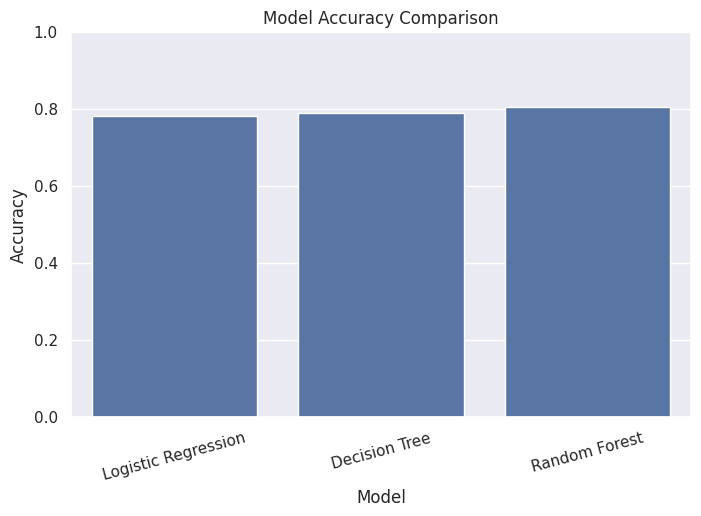


===== LOGISTIC REGRESSION =====
Accuracy : 0.7821229050279329
Precision: 0.8448275862068966
Recall   : 0.620253164556962
F1 Score : 0.7153284671532847

===== DECISION TREE =====
Accuracy : 0.7877094972067039
Precision: 0.7808219178082192
Recall   : 0.7215189873417721
F1 Score : 0.75

===== RANDOM FOREST =====
Accuracy : 0.8044692737430168
Precision: 0.8142857142857143
Recall   : 0.7215189873417721
F1 Score : 0.7651006711409396


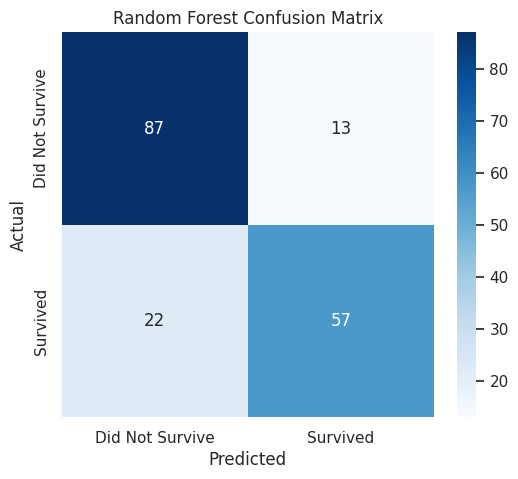


Random Forest Classification Report
-----------------------------------
                 precision    recall  f1-score   support

Did Not Survive       0.80      0.87      0.83       100
       Survived       0.81      0.72      0.77        79

       accuracy                           0.80       179
      macro avg       0.81      0.80      0.80       179
   weighted avg       0.81      0.80      0.80       179


Sample Prediction Results
-------------------------
Passenger 1: Actual = Survived, Predicted = Survived
Passenger 2: Actual = Did Not Survive, Predicted = Did Not Survive
Passenger 3: Actual = Survived, Predicted = Survived
Passenger 4: Actual = Did Not Survive, Predicted = Did Not Survive
Passenger 5: Actual = Survived, Predicted = Did Not Survive
Passenger 6: Actual = Did Not Survive, Predicted = Did Not Survive
Passenger 7: Actual = Survived, Predicted = Did Not Survive
Passenger 8: Actual = Did Not Survive, Predicted = Did Not Survive
Passenger 9: Actual = Survived, Pre

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(x_train, y_train)
dt_prediction = decision_tree.predict(x_test)
dt_accuracy = accuracy_score(y_test, dt_prediction)

print("Decision Tree Accuracy:", dt_accuracy)

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(x_train, y_train)
rf_prediction = random_forest.predict(x_test)
rf_accuracy = accuracy_score(y_test, rf_prediction)

print("Random Forest Accuracy:", rf_accuracy)
lr_prediction = model.predict(x_test)

lr_accuracy = accuracy_score(y_test, lr_prediction)

print("\nModel Comparison")
print("--------------------------")
print("Logistic Regression:", lr_accuracy)
print("Decision Tree:      ", dt_accuracy)
print("Random Forest:      ", rf_accuracy)
model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

accuracies = [
    lr_accuracy,
    dt_accuracy,
    rf_accuracy
]

plt.figure(figsize=(8, 5))
sns.barplot(x=model_names, y=accuracies)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()


print("\n===== LOGISTIC REGRESSION =====")
print("Accuracy :", accuracy_score(y_test, lr_prediction))
print("Precision:", precision_score(y_test, lr_prediction))
print("Recall   :", recall_score(y_test, lr_prediction))
print("F1 Score :", f1_score(y_test, lr_prediction))

print("\n===== DECISION TREE =====")
print("Accuracy :", accuracy_score(y_test, dt_prediction))
print("Precision:", precision_score(y_test, dt_prediction))
print("Recall   :", recall_score(y_test, dt_prediction))
print("F1 Score :", f1_score(y_test, dt_prediction))

print("\n===== RANDOM FOREST =====")
print("Accuracy :", accuracy_score(y_test, rf_prediction))
print("Precision:", precision_score(y_test, rf_prediction))
print("Recall   :", recall_score(y_test, rf_prediction))
print("F1 Score :", f1_score(y_test, rf_prediction))

cm = confusion_matrix(y_test, rf_prediction)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()




print("\nRandom Forest Classification Report")
print("-----------------------------------")

print(
    classification_report(
        y_test,
        rf_prediction,
        target_names=["Did Not Survive", "Survived"]
    )
)




print("\nSample Prediction Results")
print("-------------------------")

for i in range(10):
    actual = y_test.iloc[i] if hasattr(y_test, "iloc") else y_test[i]
    predicted = rf_prediction[i]

    actual_result = "Survived" if actual == 1 else "Did Not Survive"
    predicted_result = "Survived" if predicted == 1 else "Did Not Survive"

    print(
        f"Passenger {i+1}: "
        f"Actual = {actual_result}, "
        f"Predicted = {predicted_result}"
    )